# Week 2 class

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/goodman-imperial/discrete-maths-classes/blob/main/week-2-class.ipynb)

In this week's class we'll dive into the prime factoring algorithm and see how different algorithmic choices can affect performance.

We'll start by importing some standard libraries, don't worry about understanding this if you don't speak Python.

In [71]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Introduction

Now we'll do the stupidest possible algorithm to count the number of primes less than n. This algorithm is even stupider than the one from the videos. See if you can understand how it works and why it's even stupider.

In [72]:
def stupidest_num_primes_less_than(n):
    #loops through every num between 2 to n 
    #only returns after the loop, not when a factor is found
    def is_prime(n):
        if n==1:
            return False
        no_factors = True
        for j in range(2, n):
            if n%j==0:
                no_factors = False
        return no_factors
    
    #loops through every num from 2 to n 
    #calls is_prime function for each num to check if prime
    #increments count every time prime is found
    count = 0
    for i in range(2, n+1):
        if is_prime(i):
            count += 1
    return count

Now we're going to plot the number of primes less than n and the same thing on a log-log plot. Later, we'll do some more plotting, and you can just re-use this code with slight modifications.

We also fit a best fit line to the log-log plot. Why is this useful? It gives us a rough idea of how fast the algorithm is growing (although it's not perfect). How does that work? Well, suppose that $\log y = a \log x + b$ for some constants $a$ and $b$, then by taking exponentials of both sides we can see that $y=e^b x^a$, in other words $y=\Theta(x^a)$ in complexity notation. So the slope of the best fit line of a log-log plot gives you an approximate value for the polynomial power if the function grows like a polynomial.

WARNING! This will give you a value even if the growth is NOT polynomial. Indeed, the examples below are not polynomial, this is just to get a rough idea of how quickly they're growing.

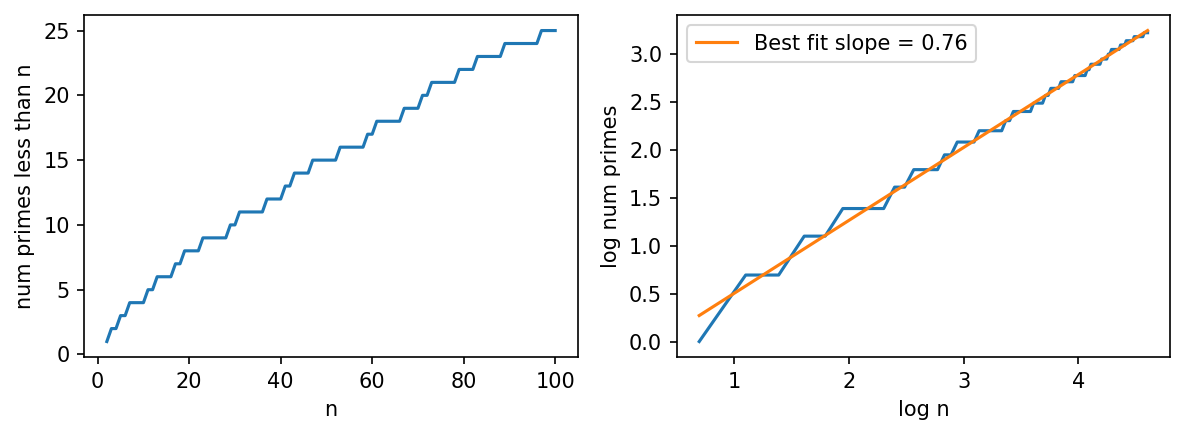

In [73]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of primes less than n
numprimes = np.array([stupidest_num_primes_less_than(n) for n in N])

# Matplotlib code (feel free to reuse)
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left
plt.plot(N, numprimes)                   # plot N on the x-axis and numprimes on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num primes less than n')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numprimes))   # np.log uses function log from numpy package
# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numprimes), 1)
plt.plot(np.log(N), slope*np.log(N)+intercept, label=f'Best fit slope = {slope:.2f}')
# then we label it
plt.xlabel('log n')
plt.ylabel('log num primes')
plt.legend(loc='best')
plt.tight_layout(); # and this makes everything use space nicely

# Class questions

## Q1: Count and plot the number of operations

The first task is to add code to the prime counting function to count the number of operations it does. Here's an example for a different function you can adapt.

In [74]:
#example function
operation_count = 0

def sum_of_n(n):
    global operation_count
    sum = 0
    operation_count += 1 # we set sum to 0
    for i in range(1, n+1):
        operation_count += 2 # we add 1 to i and compare to n+1
        sum += i
        operation_count += 1 # we add i to sum
    return sum

In this function you can see that the global variable ``operation_count`` starts at 0 and is increased repeatedly while the function is called. We've added 2 and then 1 in the loop body, but actually because constants don't matter for complexity notation, you can just add 1 in the loop body.

Right, now go ahead and adapt this idea to count the number of operations in ``stupidest_num_primes_less_than(n)``, and plot that and fit a best line to the log-log plot as above (just adapt that code).

Does it do what you'd expect from the lecture videos?

In [75]:
opcount = 0

def opcount_stupidest_num_primes_less_than(n):
    global opcount
    
    def is_prime(n):
        global opcount
        
        if n==1:
            opcount += 1
            return False
        
        no_factors = True
        opcount += 1

        for j in range(2, n):
            opcount += 2
            if n%j==0:
                opcount += 1
                no_factors = False
                opcount += 1

        return no_factors

    count = 0
    opcount += 1

    for i in range(2, n+1):
        opcount += 2
        if is_prime(i):
            opcount += 1
            count += 1
            opcount += 1

    op_count = opcount
    opcount = 0

    return op_count

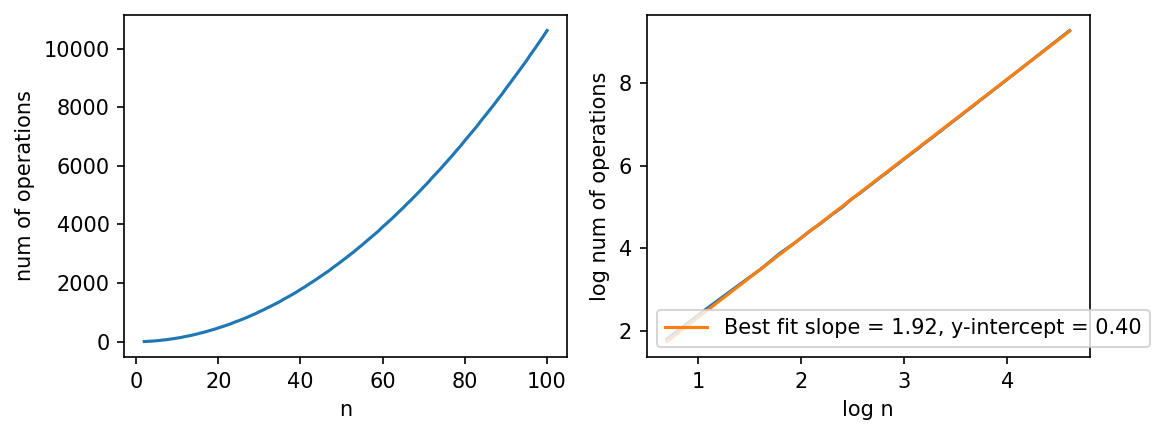

In [76]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of operations carried out
numops = np.array([opcount_stupidest_num_primes_less_than(n) for n in N])

# Matplotlib code
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left -> 1=row, 2=col, 1=1st subplot(left)
plt.plot(N, numops)                      # plot N on the x-axis and numops on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num of operations')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numops))      # np.log uses function log from numpy package

# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numops), 1)
plt.plot(
        np.log(N), 
        slope*np.log(N)+intercept, 
        label=f'Best fit slope = {slope:.2f}, y-intercept = {intercept:.2f}' #2f means 2 sig fig
        )
plt.xlabel('log n')
plt.ylabel('log num of operations')
plt.legend(loc='best') #legend is the key for labels of plots; loc=best chooses position that minimises overlap with plotted data
plt.tight_layout(); # and this makes everything use space nicely

a, b in logy = alogx + b are 1.92 and 0.40 respectively   
Therefore y = e^0.4(x^1.92)   
Making this algorithm ~ $\Theta(n^2)$

## Version from lectures

Now modify your code to use the slightly less naive algorithm given in the lectures, where you break out of the inner loop once you find that a number is not prime. Analyse this. How does it compare?

In [77]:
def opcount_less_stupid_num_primes_less_than(n):
    global opcount
    
    def is_prime(n):
        global opcount
        
        if n==1:
            opcount += 1
            return False 

        for j in range(2, n):
            opcount += 2
            if n%j==0:
                opcount += 1
                return False

        return True

    count = 0
    opcount += 1

    for i in range(2, n+1):
        opcount += 2
        if is_prime(i):
            opcount += 1
            count += 1
            opcount += 1

    op_count = opcount
    opcount = 0

    return op_count

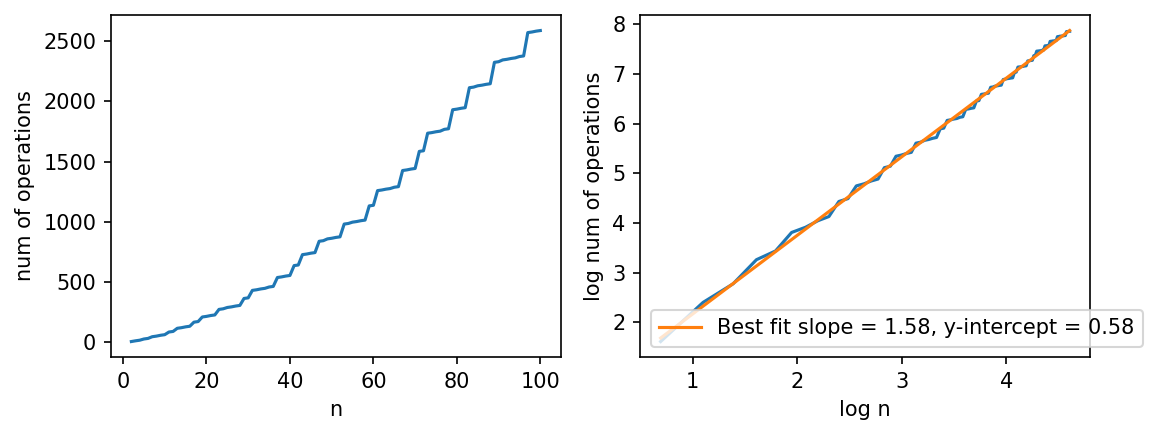

In [78]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of operations carried out
numops = np.array([opcount_less_stupid_num_primes_less_than(n) for n in N])

# Matplotlib code
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left -> 1=row, 2=col, 1=1st subplot(left)
plt.plot(N, numops)                      # plot N on the x-axis and numops on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num of operations')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numops))      # np.log uses function log from numpy package

# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numops), 1)
plt.plot(
        np.log(N), 
        slope*np.log(N)+intercept, 
        label=f'Best fit slope = {slope:.2f}, y-intercept = {intercept:.2f}' #2f means 2 sig fig
        )
plt.xlabel('log n')
plt.ylabel('log num of operations')
plt.legend(loc='best') #legend is the key for labels of plots; loc=best chooses position that minimises overlap with plotted data
plt.tight_layout(); # and this makes everything use space nicely

The polynomial of n reduces due to the early return from is_prime()

## Prime factor algorithm

Actually, to check if a number $n$ is prime, you don't need to just every possible factor below $n$, only up to $\sqrt{n}$. Why? Because if $m$ is a factor of $n$, then $n/m$ must also be a factor, and at least one of $m$ or $n/m$ must be smaller than $\sqrt{n}$. If both $m$ and $n/m$ were larger than $\sqrt{n}$ then the product of them both would be larger than $n$, but the product is just $n$.

Adapt your code to use this idea and compare its performance. This is known as the prime factor algorithm.

In [79]:
def prime_factor(n):
    global opcount
    
    def is_prime(n):
        global opcount
        
        if n==1:
            opcount += 1
            return False 

        for j in range(2, int(np.sqrt(n) + 1)):
            opcount += 2
            if n%j==0:
                opcount += 1
                return False

        return True

    count = 0
    opcount += 1

    for i in range(2, n+1):
        opcount += 2
        if is_prime(i):
            opcount += 1
            count += 1
            opcount += 1

    op_count = opcount
    opcount = 0

    return op_count

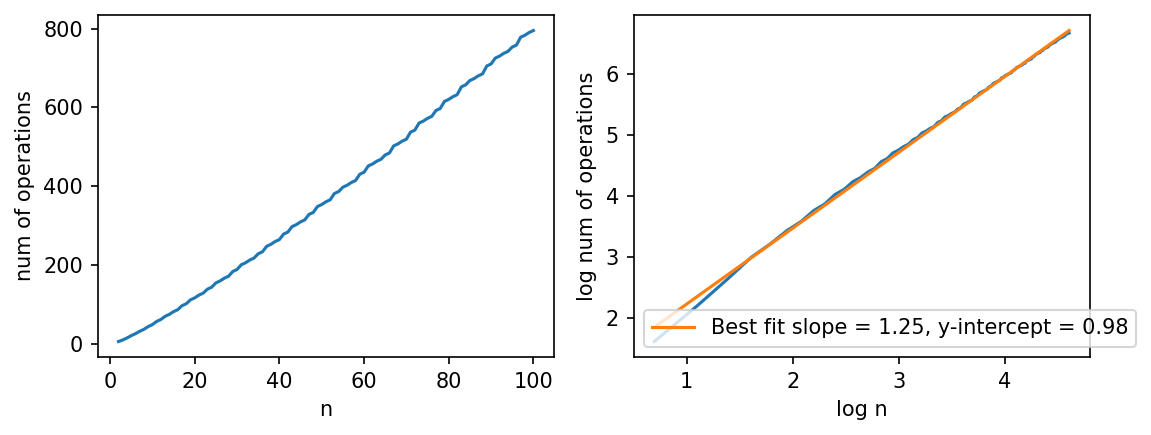

In [80]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of operations carried out
numops = np.array([prime_factor(n) for n in N])

# Matplotlib code
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left -> 1=row, 2=col, 1=1st subplot(left)
plt.plot(N, numops)                      # plot N on the x-axis and numops on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num of operations')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numops))      # np.log uses function log from numpy package

# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numops), 1)
plt.plot(
        np.log(N), 
        slope*np.log(N)+intercept, 
        label=f'Best fit slope = {slope:.2f}, y-intercept = {intercept:.2f}' #2f means 2 sig fig
        )
plt.xlabel('log n')
plt.ylabel('log num of operations')
plt.legend(loc='best') #legend is the key for labels of plots; loc=best chooses position that minimises overlap with plotted data
plt.tight_layout(); # and this makes everything use space nicely

## Sieve of Eratosthenes

Finally, a much better algorithm is like the table method for the Fibonacci series. Rather than recomputing from scratch each time whether a number is prime, we re-use the calculations we've already made. In this case, start with a table of values saying all values from 2 to $n$ are prime. Loop through this from 2 to $n$, and if your value is prime, set all the multiples of it to be False. So in the first step you'd see that ``isprime[2]==True`` so you'd set ``isprime[4] = False``, ``isprime[6] = False`` and so on. Keep going until you've got to $\sqrt{n}$ and then count the number of values where ``isprime`` is True.

This algorithm is called the Sieve of Eratosthenes. Implement this algorithm and compare its performance.

In [81]:
def sieve(n):
    global opcount
    isprime = {}
    
    for i in range(2, n+1):
        opcount += 2
        isprime[i] = True
        opcount += 1

    for i in range(2, int(np.sqrt(n) + 1)):
        opcount += 3
        m = n//i
        opcount += 1
        for j in range (m + 1):
            opcount += 2
            isprime[j*i] = False
            opcount += 1

    count = 0
    for i in range (2, n+1):
        opcount += 2
        if isprime[i] == True:
            opcount += 1
            count += 1
            opcount += 1

    op_count = opcount
    opcount = 0

    return op_count

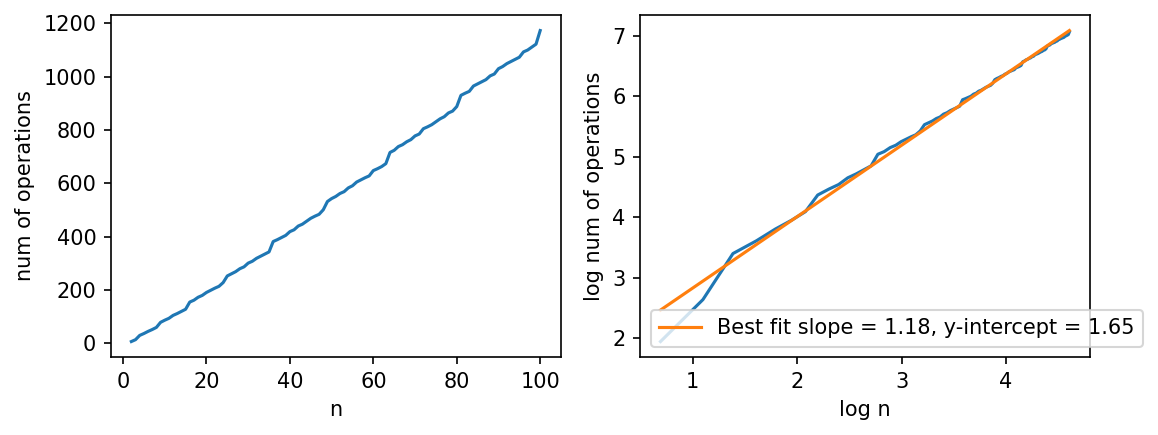

In [82]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of operations carried out
numops = np.array([sieve(n) for n in N])

# Matplotlib code
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left -> 1=row, 2=col, 1=1st subplot(left)
plt.plot(N, numops)                      # plot N on the x-axis and numops on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num of operations')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numops))      # np.log uses function log from numpy package

# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numops), 1)
plt.plot(
        np.log(N), 
        slope*np.log(N)+intercept, 
        label=f'Best fit slope = {slope:.2f}, y-intercept = {intercept:.2f}' #2f means 2 sig fig
        )
plt.xlabel('log n')
plt.ylabel('log num of operations')
plt.legend(loc='best') #legend is the key for labels of plots; loc=best chooses position that minimises overlap with plotted data
plt.tight_layout(); # and this makes everything use space nicely

### Sieve of Eratosthenes
Time complexity is ~ $\Theta(n)$

## Comparison

Finally, plot all the algorithms on the same axes to compare their performance.

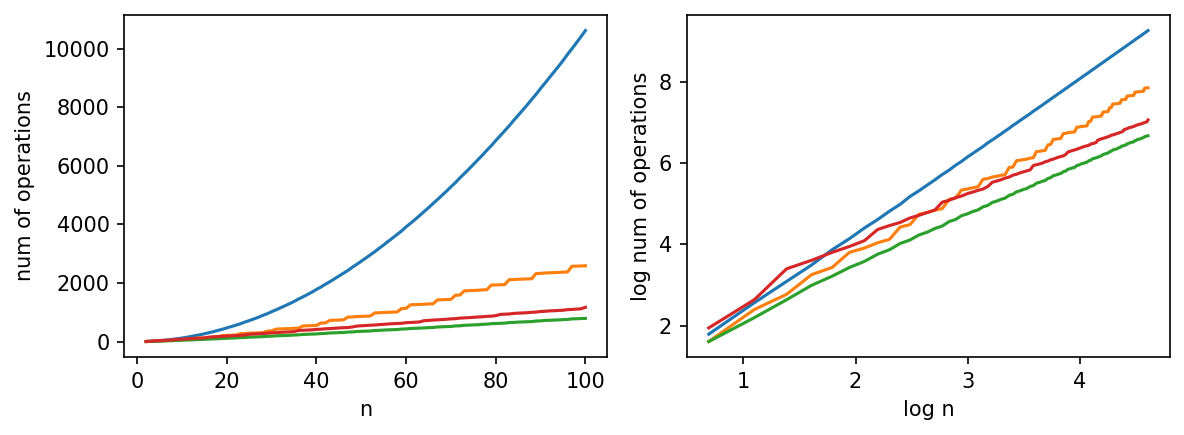

In [83]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of operations carried out
numops_stupid = np.array([opcount_stupidest_num_primes_less_than(n) for n in N])
numops_less_stupid = np.array([opcount_less_stupid_num_primes_less_than(n) for n in N])
numops_prime_factor = np.array([prime_factor(n) for n in N])
numops_sieve = np.array([sieve(n) for n in N])

# Matplotlib code
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left -> 1=row, 2=col, 1=1st subplot(left)
plt.plot(N, numops_stupid)
plt.plot(N, numops_less_stupid)
plt.plot(N, numops_prime_factor)
plt.plot(N, numops_sieve)       
plt.xlabel('n')
plt.ylabel('num of operations')

plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numops_stupid))
plt.plot(np.log(N), np.log(numops_less_stupid))
plt.plot(np.log(N), np.log(numops_prime_factor))
plt.plot(np.log(N), np.log(numops_sieve))
plt.xlabel('log n')
plt.ylabel('log num of operations')
plt.tight_layout(); # and this makes everything use space nicely